# 04 · Modelos paramétricos AFT / Accelerated failure time models

$$\log T = \beta^\top x + \sigma\,\varepsilon$$

Em vez de multiplicar o *risco*, as covariáveis **aceleram ou desaceleram o tempo**:
$\exp(\beta_j)$ é um **time ratio**; TR = 1,2 significa permanência 20% **maior**.
Vantagem: não assume riscos proporcionais e permite extrapolar a curva.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))  # works even without `pip install -e .`
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from turnover_survival import config, data, nonparametric, models, evaluation

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:.3f}".format)
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)
T, E = config.DURATION_COL, config.EVENT_COL

df = data.load_clean()
print(f"{len(df)} employees | {df[E].sum()} left | {1 - df[E].mean():.1%} censored")

1116 employees | 560 left | 49.8% censored


In [2]:
from lifelines import WeibullFitter, LogNormalFitter, LogLogisticFitter, ExponentialFitter
from lifelines.plotting import qq_plot

X = data.make_design_matrix(df)
train, test = data.split(X)

## Qual distribuição? / Which distribution? (univariate)

,distribution,AIC
3,LogLogistic,5926.850
2,LogNormal,5926.986
1,Weibull,5927.470
0,Exponential,5929.483


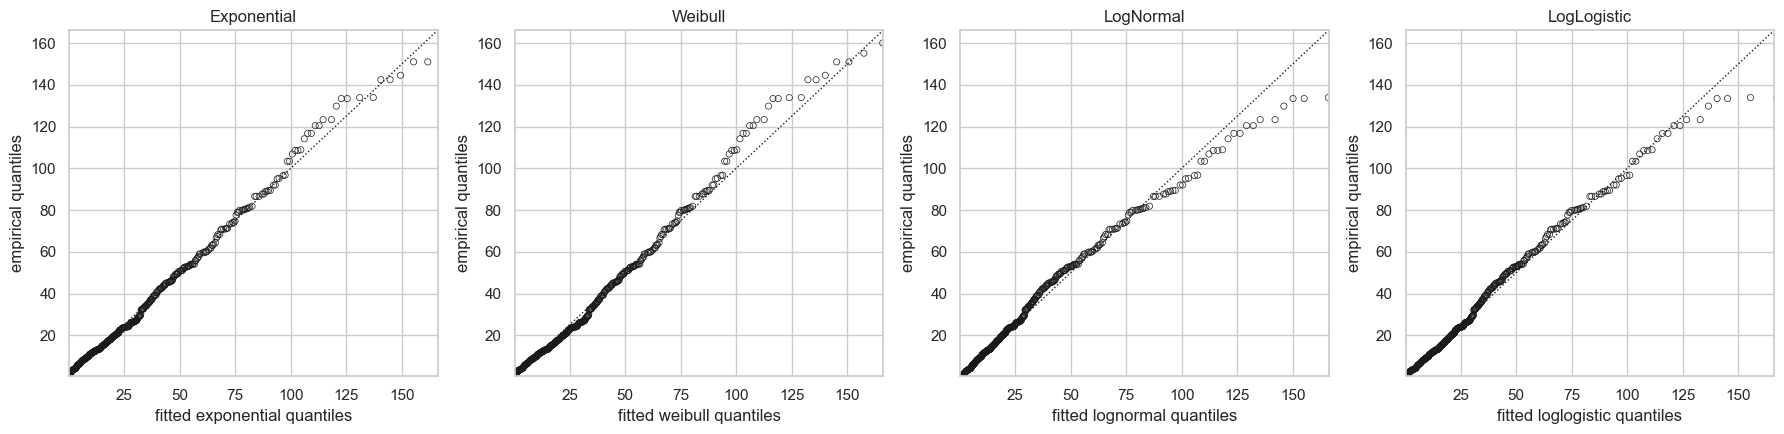

In [3]:
fitters = [ExponentialFitter(), WeibullFitter(), LogNormalFitter(), LogLogisticFitter()]
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
rows = []
for f, ax in zip(fitters, axes):
    f.fit(df[T], df[E])
    qq_plot(f, ax=ax)
    ax.set_title(f.__class__.__name__.replace("Fitter", ""))
    rows.append({"distribution": f.__class__.__name__.replace("Fitter", ""), "AIC": f.AIC_})
fig.tight_layout()
fig.savefig(config.FIGURES_DIR / "04_qq.png", dpi=120, bbox_inches="tight")
pd.DataFrame(rows).sort_values("AIC")

Pontos sobre a diagonal no QQ-plot indicam bom ajuste da distribuição.

## AFT com covariáveis / AFT regression

In [4]:
aft = models.fit_aft_models(train)
models.compare_aft(aft)

,model,AIC,log_likelihood,concordance_train
0,LogNormal,4289.374,-2101.687,0.666
1,Weibull,4292.644,-2103.322,0.659
2,LogLogistic,4297.257,-2105.629,0.666


In [5]:
best_name = models.compare_aft(aft).iloc[0]["model"]
best = aft[best_name]
print("Best by AIC:", best_name)

s = best.summary.loc[best.summary.index.get_level_values(0).str.contains("lambda_|mu_|alpha_", regex=True)]
s = s.reset_index().query("covariate != 'Intercept'")
s["time_ratio"] = np.exp(s["coef"])
s[["covariate", "time_ratio", "exp(coef) lower 95%", "exp(coef) upper 95%", "p"]].sort_values("time_ratio")

Best by AIC: LogNormal


,covariate,time_ratio,exp(coef) lower 95%,exp(coef) upper 95%,p
10,industry_building,0.410,0.249,0.676,0.000
27,profession_manage,0.529,0.267,1.048,0.068
11,industry_consult,0.577,0.387,0.861,0.007
9,industry_banks,0.607,0.434,0.847,0.003
6,greywage_grey,0.609,0.454,0.817,0.001
18,industry_state,0.630,0.405,0.981,0.041
22,profession_businessdevelopment,0.659,0.382,1.138,0.135
25,profession_etc,0.687,0.424,1.115,0.129
23,profession_commercial,0.701,0.363,1.353,0.290
30,profession_sales,0.717,0.462,1.112,0.137


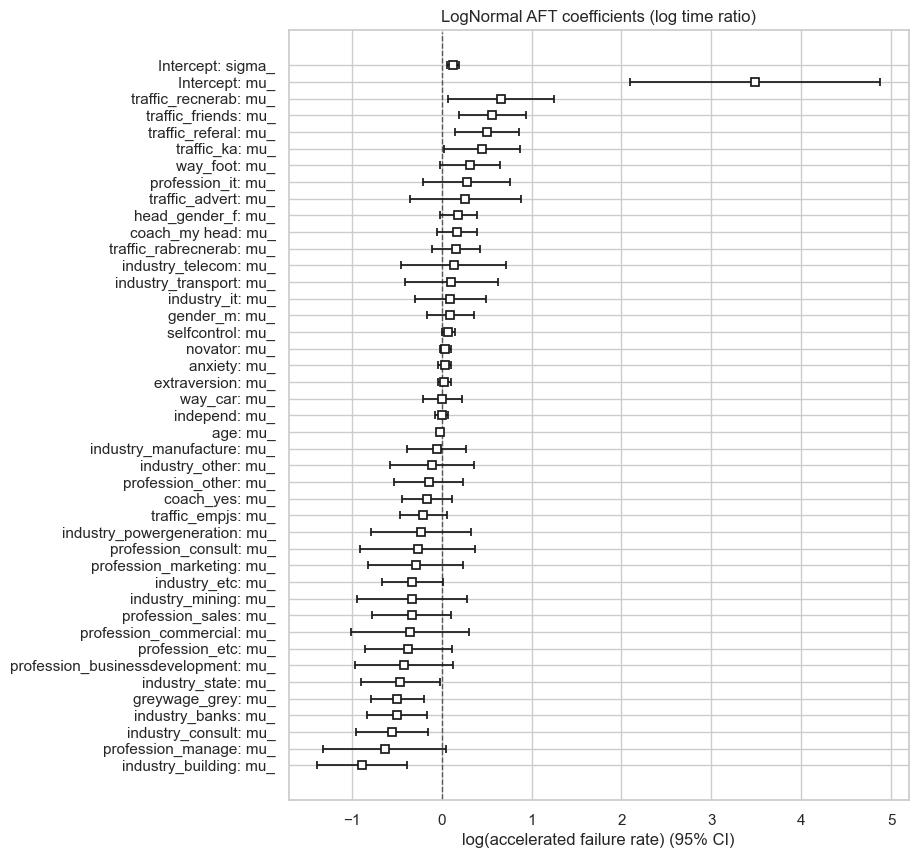

In [6]:
fig, ax = plt.subplots(figsize=(8, 10))
best.plot(ax=ax)
ax.set_title(f"{best_name} AFT coefficients (log time ratio)")
fig.savefig(config.FIGURES_DIR / "04_aft_coefs.png", dpi=120, bbox_inches="tight")

**Leitura:** time ratio < 1 → a característica **encurta** o tempo até a saída (maior risco);
> 1 → **alonga** a permanência.

## Mediana prevista no teste / Predicted median tenure

In [7]:
pred = best.predict_median(models.features(test)).rename("predicted_median_months")
pd.concat([test[[T, E]], pred], axis=1).head(10)

,stag,event,predicted_median_months
0,7.031,1,45.127
1,22.965,1,27.207
2,15.934,1,33.412
19,45.372,1,61.949
27,3.253,1,44.799
31,28.156,1,66.338
33,87.688,1,37.811
43,9.101,1,37.615
51,14.949,1,47.275
53,50.727,1,50.408


### Conclusões / Takeaways
> _Preencha após rodar com os dados reais. / Fill in after running on the real data._